<a href="https://colab.research.google.com/github/Zheleikina/ML_Zheleikina/blob/main/%D0%9B%D0%A012_%D0%96%D0%B5%D0%BB%D0%B5%D0%B9%D0%BA%D1%96%D0%BD%D0%B0_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 12
## Рекурентні нейронні мережі (RNN, LSTM). Генерація тексту та підбір гіперпараметрів

**ПІБ студента:** Желейкіна Аліна  
**Група:** 3-9  
**Дата:** 25.11.2026

### Мета роботи
Ознайомитися з принципами обробки текстових послідовностей за допомогою **SimpleRNN** та **LSTM**, навчитися підготовлювати текстові дані, будувати й навчати модель передбачення наступного слова, генерувати текст і підбирати гіперпараметри за допомогою **Keras Tuner**.

### Очікуваний результат
- Побудована й навчена модель `Embedding → SimpleRNN → LSTM → Dropout → Dense`.
- Графіки втрат і точності, приклад згенерованого тексту.
- Результат автоматичного підбору гіперпараметрів і порівняння двох моделей.

**Інструкція:** виконуйте кроки послідовно, заповнюйте порожні комірки Python власним кодом. Не видаляйте результати запуску — вони потрібні для перевірки. Рекомендоване середовище: Google Colab або Jupyter Notebook з TensorFlow.

## Частина 1. Створення моделі для передбачення наступного слова

### 1. Імпорт бібліотек
Імпортуйте:
- `numpy` як `np`, `matplotlib.pyplot` як `plt`;
- `Sequential` із `tensorflow.keras.models`;
- `Dense`, `SimpleRNN`, `LSTM`, `Embedding`, `Dropout`;
- `Tokenizer` із `tensorflow.keras.preprocessing.text`;
- `to_categorical` із `tensorflow.keras.utils`.

**Завдання:** переконайтеся, що всі бібліотеки імпортуються без помилок.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Embedding, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical

### 2. Вхідний текст для навчання
Створіть рядкову змінну `texts` із наведеним фрагментом вірша. Саме цей текст використовується у вихідному прикладі лабораторної роботи.

```text
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..
```

**Завдання:** виведіть початковий текст або перші 100 його символів.

In [2]:
texts = """Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?.."""

print(texts)

Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..


### 3. Попередня обробка та токенізація
1. Видаліть із `texts` можливий символ `\ufeff`.
2. Задайте `maxWordsCount = 1000`.
3. Створіть `Tokenizer` із такими налаштуваннями: `num_words=maxWordsCount`, `lower=True`, `split=' '`, `char_level=False`. Для `filters` використайте набір знаків пунктуації з вихідного прикладу, зокрема `!`, `?`, `.`, `,`, тире та лапки.
4. Навчіть токенізатор на тексті за допомогою `fit_on_texts()`.
5. Виведіть кількість знайдених унікальних слів та кілька відповідностей зі словника `word_index`.

**Підказка:** метод `fit_on_texts()` будує словник відповідностей слів і числових індексів.

In [3]:
texts = texts.replace('\ufeff', '')

maxWordsCount = 1000

tokenizer = Tokenizer(
    num_words=maxWordsCount,
    lower=True,
    split=' ',
    char_level=False,
    filters='!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~«»—–„“”'
)

tokenizer.fit_on_texts([texts])

print("Кількість унікальних слів:", len(tokenizer.word_index))
print("Перші 10 відповідностей слово → індекс:")

for word, index in list(tokenizer.word_index.items())[:10]:
    print(word, "→", index)

Кількість унікальних слів: 39
Перші 10 відповідностей слово → індекс:
не → 1
на → 2
вас → 3
думи → 4
мої → 5
лихо → 6
в → 7

лихо → 8
мені → 9
з → 10


### 4. Формування навчальної вибірки
Перетворіть текст на послідовність цілих чисел методом `texts_to_sequences()` і збережіть числову послідовність у змінній `res` як масив NumPy.

Задайте **`inp_words = 3`**. Сформуйте:
- `X` — послідовності з **трьох** сусідніх слів;
- `Y` — **наступне слово** після кожної послідовності у форматі one-hot (`to_categorical`, `num_classes=maxWordsCount`).

Перевірте розміри `X` і `Y`, виведіть перший приклад та його цільове слово.

**Підказка:** кількість навчальних прикладів дорівнює `len(res) - inp_words`.

In [4]:
res = np.array(tokenizer.texts_to_sequences([texts])[0])

inp_words = 3

X = []
Y = []

for i in range(inp_words, len(res)):
    X.append(res[i - inp_words:i])
    Y.append(res[i])

X = np.array(X)
Y = to_categorical(Y, num_classes=maxWordsCount)

print("Розмір X:", X.shape)
print("Розмір Y:", Y.shape)

print("\nПерший приклад X:", X[0])
print("Цільове слово:", tokenizer.index_word[res[inp_words]])

Розмір X: (47, 3)
Розмір Y: (47, 1000)

Перший приклад X: [4 5 4]
Цільове слово: мої


### 5. Побудова рекурентної нейронної мережі
Створіть модель `Sequential` із такою архітектурою (як у вихідному ноутбуці):

1. `Embedding(maxWordsCount, 300, input_length=inp_words)` — векторні представлення слів;
2. `SimpleRNN(128, activation='tanh', return_sequences=True)`;
3. `LSTM(128, activation='tanh')`;
4. `Dropout(0.2)`;
5. `Dense(128, activation='relu')`;
6. `Dense(maxWordsCount, activation='softmax')`.

Збережіть модель у змінній `model`.

**Питання:** чому для `SimpleRNN` необхідний параметр `return_sequences=True`, якщо після нього йде шар `LSTM`?

In [6]:
model = Sequential([
    Embedding(maxWordsCount, 300, input_length=inp_words),
    SimpleRNN(128, activation='tanh', return_sequences=True),
    LSTM(128, activation='tanh'),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dense(maxWordsCount, activation='softmax')
])
model.build(input_shape=(None, inp_words))
model.summary()
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 300)         │       300,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 3, 128)         │        54,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1000)           │       129,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 632,008 (2.41 MB)

 Trainable params: 632,008 (2.41 MB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 300)         │       300,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 3, 128)         │        54,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1000)           │       129,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 632,008 (2.41 MB)

 Trainable params: 632,008 (2.41 MB)

 Non-trainable params: 0 (0.00 B)

return_sequences=True потрібний, щоб SimpleRNN передавав до LSTM результати для всіх слів, а не лише для останнього. Це дозволяє LSTM обробити всю послідовність.

### 6. Компіляція та перегляд архітектури
Скомпілюйте `model` із параметрами:
- оптимізатор — `adam`;
- функція втрат — `categorical_crossentropy`;
- метрика — `accuracy`.

Виведіть `model.summary()` і запишіть кількість параметрів моделі.

In [7]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 300)         │       300,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 3, 128)         │        54,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1000)           │       129,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 632,008 (2.41 MB)

 Trainable params: 632,008 (2.41 MB)

 Non-trainable params: 0 (0.00 B)

### 7. Навчання моделі
Навчіть модель на `X` та `Y` із параметрами **`batch_size=32`** і **`epochs=50`**. Збережіть історію навчання у змінну `history`.

**Завдання:** виведіть значення точності та функції втрат для останньої епохи.

In [8]:
history = model.fit(
    X, Y,
    batch_size=32,
    epochs=50
)

print("Точність останньої епохи:", history.history['accuracy'][-1])
print("Функція втрат останньої епохи:", history.history['loss'][-1])

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.0000e+00 - loss: 6.9075
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.1489 - loss: 6.8942
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.5532 - loss: 6.8795
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.6170 - loss: 6.8615
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5957 - loss: 6.8349
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.5745 - loss: 6.7930
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5106 - loss: 6.7231
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.2553 - loss: 6.6127
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.2340 - loss: 6.3838
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.1277 - loss: 5.9554
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.1489 - loss: 5.2530
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.1277 - loss: 4.36

### 8. Візуалізація навчання
Використовуючи `history.history`, побудуйте **два графіки поруч**:
- функція втрат `loss` залежно від епохи;
- точність `accuracy` залежно від епохи.

Додайте назви графіків, підписи осей і легенди.

**Короткий аналіз:** як змінювалися `loss` та `accuracy`? Чи достатньо цих графіків, щоб оцінити якість моделі на новому тексті?

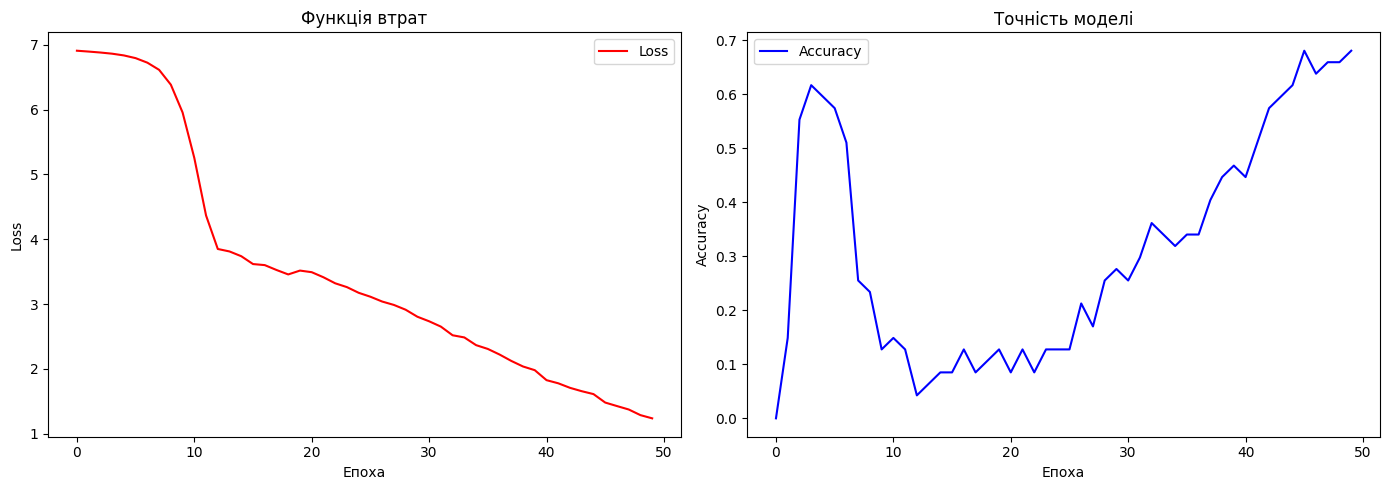

In [9]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Loss', color='red')
plt.title('Функція втрат')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Accuracy', color='blue')
plt.title('Точність моделі')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

Під час навчання значення loss поступово зменшувалося, а accuracy загалом зростала. Це свідчить про те, що модель навчається та краще запам'ятовує закономірності тексту.

### 9. Генерація нового тексту
Реалізуйте функцію **`buildPhrase(texts, str_len=20)`**, яка:
1. Перетворює початковий текст на індекси слів за допомогою `tokenizer`;
2. На кожному кроці передає моделі **останні `inp_words` індексів**;
3. Отримує прогноз `model.predict()`, визначає індекс найбільш імовірного слова через `argmax`;
4. Додає нове слово до послідовності, використовуючи `tokenizer.index_word`;
5. Повертає згенеровану фразу.

Перевірте роботу функції на початковій фразі **`"Думи мої думи"`**, згенеруйте **20 слів**.

**Зверніть увагу:** початкова фраза має містити щонайменше три відомі токенізатору слова. Якщо слово не знайдено, передбачте зрозумілу обробку цього випадку.

In [10]:
def buildPhrase(texts, str_len=20):
    sequence = tokenizer.texts_to_sequences([texts])[0]

    if len(sequence) < inp_words:
        raise ValueError("Початкова фраза повинна містити щонайменше три відомі слова.")

    result = texts

    for _ in range(str_len):
        x = np.array(sequence[-inp_words:]).reshape(1, inp_words)
        prediction = model.predict(x, verbose=0)
        index = np.argmax(prediction)

        word = tokenizer.index_word.get(index)

        if word is None:
            break

        result += " " + word
        sequence.append(index)

    return result


generated_text = buildPhrase("Думи мої думи", str_len=20)

print("Згенерований текст:")
print(generated_text)

Згенерований текст:
Думи мої думи мої 
лихо мої з вами з стали на стали рядами сміх рядами вас на 
поливали на сміх не сміх в


## Частина 2. Автоматичний підбір гіперпараметрів (Keras Tuner)

### 10. Встановлення та імпорт Keras Tuner
У Google Colab або Jupyter Notebook встановіть (за потреби) пакет `keras-tuner`. Імпортуйте його під псевдонімом `kt`.

**Підказка:** для встановлення пакета в ноутбуці використовуйте `%pip install keras-tuner`.

Повторно створювати `X` та `Y` не потрібно: використайте вибірку з Частини 1.

In [11]:
%pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]


In [12]:
import keras_tuner as kt

print("Keras Tuner успішно імпортовано!")

Keras Tuner успішно імпортовано!


### 11. Створення функції `build_model(hp)`
Опишіть функцію, яка будує та компілює модель і дає змогу змінювати гіперпараметри:

| Гіперпараметр | Простір пошуку |
|---|---|
| `embedding_dim` | від 128 до 512, крок 64 |
| `rnn_units` | від 64 до 256, крок 64 |
| `lstm_units` | від 64 до 256, крок 64 |
| `dropout_rate` | від 0.1 до 0.5, крок 0.1 |
| `dense_units` | від 64 до 256, крок 64 |
| `optimizer` | `adam` або `rmsprop` |

Збережіть структуру шарів із Частини 1: `Embedding → SimpleRNN → LSTM → Dropout → Dense → Dense`.

**Підказка:** використовуйте `hp.Int()`, `hp.Float()` і `hp.Choice()`; останній шар має `maxWordsCount` нейронів із `softmax`. Функція `build_model(hp)` повинна повертати скомпільовану модель.

In [13]:
def build_model(hp):
    model = Sequential([
        Embedding(
            maxWordsCount,
            hp.Int('embedding_dim', min_value=128, max_value=512, step=64),
            input_length=inp_words
        ),
        SimpleRNN(
            hp.Int('rnn_units', min_value=64, max_value=256, step=64),
            activation='tanh',
            return_sequences=True
        ),
        LSTM(
            hp.Int('lstm_units', min_value=64, max_value=256, step=64),
            activation='tanh'
        ),
        Dropout(
            hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)
        ),
        Dense(
            hp.Int('dense_units', min_value=64, max_value=256, step=64),
            activation='relu'
        ),
        Dense(maxWordsCount, activation='softmax')
    ])

    optimizer = hp.Choice('optimizer', values=['adam', 'rmsprop'])

    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

### 12. Пошук найкращих параметрів
Створіть `kt.RandomSearch` із такими налаштуваннями, як у вихідному прикладі:
- `hypermodel=build_model` (або передайте `build_model` першим аргументом);
- `objective='accuracy'`;
- `max_trials=10`;
- `executions_per_trial=1`;
- `directory='my_tuning'`, `project_name='text_prediction'`.

Запустіть `tuner.search(X, Y, epochs=10, batch_size=32)`.

**Завдання:** отримайте найкращий набір параметрів через `get_best_hyperparameters(num_trials=1)` і виведіть значення всіх шести гіперпараметрів.

**Примітка:** у вихідному прикладі підбір здійснюється за *навчальною* точністю. Це навчальна демонстрація; для об’єктивнішого порівняння зазвичай використовують окрему валідаційну вибірку.

In [14]:
tuner = kt.RandomSearch(
    build_model,
    objective='accuracy',
    max_trials=10,
    executions_per_trial=1,
    directory='my_tuning',
    project_name='text_prediction'
)

tuner.search(X, Y, epochs=10, batch_size=32)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Найкращі гіперпараметри:")
print("embedding_dim:", best_hp.get('embedding_dim'))
print("rnn_units:", best_hp.get('rnn_units'))
print("lstm_units:", best_hp.get('lstm_units'))
print("dropout_rate:", best_hp.get('dropout_rate'))
print("dense_units:", best_hp.get('dense_units'))
print("optimizer:", best_hp.get('optimizer'))

Trial 10 Complete [00h 00m 04s]
accuracy: 0.4893617033958435

Best accuracy So Far: 0.4893617033958435
Total elapsed time: 00h 00m 42s
Найкращі гіперпараметри:
embedding_dim: 384
rnn_units: 192
lstm_units: 128
dropout_rate: 0.30000000000000004
dense_units: 64
optimizer: adam


### 13. Навчання моделі з підібраними параметрами
Створіть нову модель із найкращими параметрами (`tuner.hypermodel.build(best_hps)`), збережіть її у змінній `best_model`.

Навчіть `best_model` на `X`, `Y` із `batch_size=32`, `epochs=50`. Історію збережіть у `best_history`.

Виведіть `best_model.summary()`, а також кінцеві значення `loss` і `accuracy`.

In [15]:
best_model = tuner.hypermodel.build(best_hp)

best_history = best_model.fit(
    X, Y,
    batch_size=32,
    epochs=50
)

best_model.summary()

print("Точність останньої епохи:", best_history.history['accuracy'][-1])
print("Функція втрат останньої епохи:", best_history.history['loss'][-1])

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.0000e+00 - loss: 6.9084
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.1064 - loss: 6.8961
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.3404 - loss: 6.8834
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.4468 - loss: 6.8659
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4681 - loss: 6.8414
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.4255 - loss: 6.8089
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.3191 - loss: 6.7538
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.1915 - loss: 6.6637
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.1277 - loss: 6.4980
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.0851 - loss: 6.2023 
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.0638 - loss: 5.7137
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.0000e+00 - loss:

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 384)         │       384,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 3, 192)         │       110,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1000)           │        65,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,197,178 (8.38 MB)

 Trainable params: 732,392 (2.79 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,464,786 (5.59 MB)

Точність останньої епохи: 0.6382978558540344
Функція втрат останньої епохи: 1.5553920269012451


### 14. Графіки та генерація тексту після підбору
1. Побудуйте графіки `loss` і `accuracy` для `best_history`.
2. Порівняйте фінальні навчальні показники `model` та `best_model` в одному невеликому виводі або таблиці.
3. Згенеруйте **20 слів** із початкової фрази **`"Думи мої думи"`** за допомогою `best_model` (адаптуйте створену функцію або передайте модель їй як аргумент).
4. Порівняйте два згенеровані тексти.

**Зверніть увагу:** на такому невеликому тексті результати можуть бути нестабільними, а висока навчальна точність не означає якісної генерації нових фраз.

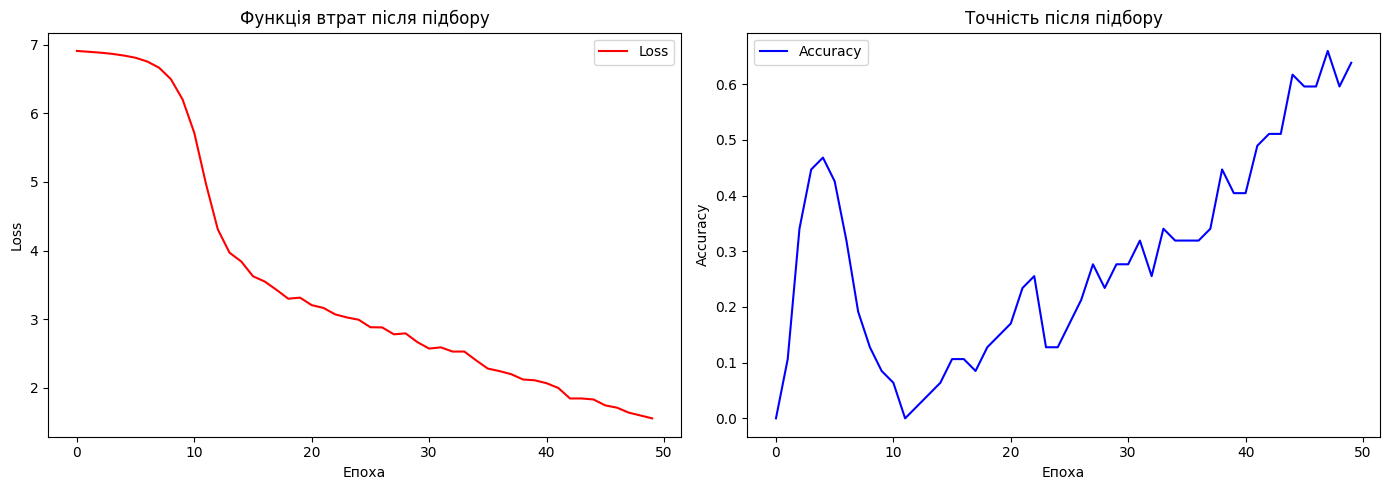

In [16]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(best_history.history['loss'], label='Loss', color='red')
plt.title('Функція втрат після підбору')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(best_history.history['accuracy'], label='Accuracy', color='blue')
plt.title('Точність після підбору')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [17]:
print("Порівняння моделей:")
print(f"{'Модель':<15} {'Accuracy':<12} {'Loss':<12}")
print("-" * 39)
print(f"{'Початкова':<15} {history.history['accuracy'][-1]:<12.4f} {history.history['loss'][-1]:<12.4f}")
print(f"{'Після підбору':<15} {best_history.history['accuracy'][-1]:<12.4f} {best_history.history['loss'][-1]:<12.4f}")

Порівняння моделей:
Модель          Accuracy     Loss        
---------------------------------------
Початкова       0.6809       1.2379      
Після підбору   0.6383       1.5554      


In [18]:
def buildPhrase(texts, model_to_use, str_len=20):
    sequence = tokenizer.texts_to_sequences([texts])[0]

    if len(sequence) < inp_words:
        raise ValueError("Початкова фраза повинна містити щонайменше три відомі слова.")

    result = texts

    for _ in range(str_len):
        x = np.array(sequence[-inp_words:]).reshape(1, inp_words)
        prediction = model_to_use.predict(x, verbose=0)
        index = np.argmax(prediction)

        word = tokenizer.index_word.get(index)

        if word is None:
            break

        result += " " + word
        sequence.append(index)

    return result


generated_best = buildPhrase("Думи мої думи", best_model, str_len=20)

print("Текст, згенерований best_model:")
print(generated_best)

Текст, згенерований best_model:
Думи мої думи мені 
лихо мені вами вами 
нащо на на папері
сумними сміх 
поливали вас вас не приспало не в не в в


In [19]:
print("Початкова модель:")
print(generated_text)

print("\nМодель після підбору параметрів:")
print(generated_best)

Початкова модель:
Думи мої думи мої 
лихо мої з вами з стали на стали рядами сміх рядами вас на 
поливали на сміх не сміх в

Модель після підбору параметрів:
Думи мої думи мені 
лихо мені вами вами 
нащо на на папері
сумними сміх 
поливали вас вас не приспало не в не в в


## Висновки
Напишіть власний висновок **5–8 речень**, спираючись на отримані результати. Висвітліть:

1. Яку роль виконують шари `Embedding`, `SimpleRNN`, `LSTM` та `Dropout`?
2. Яких значень `loss` і `accuracy` досягла початкова модель?
3. Які гіперпараметри обрав Keras Tuner?
4. Чи покращилися навчальні показники після підбору параметрів?
5. Наскільки зв’язним був згенерований текст і чому обсяг корпусу важливий?

**Висновок студента:**

_Під час роботи було створено модель для генерації тексту на основі шарів Embedding, SimpleRNN, LSTM та Dropout. Embedding перетворює слова на числові вектори, SimpleRNN і LSTM навчаються враховувати послідовність слів, а Dropout допомагає запобігти перенавчанню. Початкова модель досягла accuracy 68,09% та loss 1,2379. Keras Tuner обрав такі параметри: embedding_dim — 384, rnn_units — 192, lstm_units — 128, dropout_rate — 0,3, dense_units — 64, optimizer — Adam. Після підбору параметрів точність знизилася до 63,83%, а loss зріс до 1,5554, тому покращення не відбулося. Згенеровані тексти містили повторення слів і були недостатньо зв’язними. Це пояснюється малим обсягом навчального корпусу, якого недостатньо для повноцінного засвоєння мовних закономірностей._

---

### Що потрібно здати
Заповнений файл `.ipynb` з усім власним кодом, результатами виконання, графіками, двома прикладами згенерованого тексту, знайденими гіперпараметрами та висновками.